In [13]:
# Cell 1: Installations and Imports
import os
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import json

print("✅ All imports successful!")
print(f"TensorFlow version: {tf.__version__}")

✅ All imports successful!
TensorFlow version: 2.12.0


In [14]:
# Cell 2: Configuration and Setup

DATASET_PATH = r"C:\Study\study\Minor 1\Final\iam_words"
WORDS_TXT = os.path.join(DATASET_PATH, "words.txt")
WORDS_DIR = os.path.join(DATASET_PATH, "words")

IMG_HEIGHT, IMG_WIDTH = 64, 256
LIMIT_IMAGES = 5000 

characters = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'.- "
num_chars = len(characters)
char_to_num = {c:i for i,c in enumerate(characters)}
num_to_char = {i:c for c,i in char_to_num.items()}

MODEL_PATH = "crnn_iam_model.h5"
CONFIG_PATH = "model_config.json"

print("📝 Configuration:")
print(f"Image size: {IMG_HEIGHT}x{IMG_WIDTH}")
print(f"Characters: {characters}")
print(f"Model will be saved as: {MODEL_PATH}")

📝 Configuration:
Image size: 64x256
Characters: abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'.- 
Model will be saved as: crnn_iam_model.h5


In [15]:
# Cell 3: Utility Functions
def load_labels():
    """Load labels from words.txt file"""
    labels = {}
    with open(WORDS_TXT, "r", encoding="utf-8") as file:
        for line in file:
            if line.startswith("#"): 
                continue
            parts = line.strip().split()
            if len(parts) >= 9:
                img_path = parts[0]
                label = parts[-1].strip()
                labels[img_path] = label
    print(f"📚 Loaded {len(labels)} labels from words.txt")
    return labels

def get_image_path(img_id):
    """Construct image path from image ID"""
    parts = img_id.split("-")
    folder1 = parts[0]
    folder2 = f"{parts[0]}-{parts[1]}"
    img_file = img_id + ".png"
    return os.path.join(WORDS_DIR, folder1, folder2, img_file)

def preprocess_image(image_path):
    """Load and preprocess image"""
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))
    img = img.astype("float32") / 255.0
    return np.expand_dims(img, axis=-1)

def text_to_labels(text):
    """Convert text to numerical labels"""
    return np.array([char_to_num[c] for c in text if c in characters])

def save_model_config():
    """Save model configuration for inference"""
    config = {
        'IMG_HEIGHT': IMG_HEIGHT,
        'IMG_WIDTH': IMG_WIDTH,
        'characters': characters,
        'num_chars': num_chars
    }
    with open(CONFIG_PATH, 'w') as f:
        json.dump(config, f)
    print(f"✅ Model configuration saved to {CONFIG_PATH}")

print("✅ Utility functions defined!")

✅ Utility functions defined!


In [16]:
# Cell 4: Data Loading and Preparation
print("📦 Loading dataset...")

labels_dict = load_labels()

X, y = [], []
count = 0
failed_images = 0

print("🖼️ Loading and preprocessing images...")
for img_id, label in list(labels_dict.items())[:LIMIT_IMAGES]:
    if count >= LIMIT_IMAGES: 
        break
    
    path = get_image_path(img_id)
    if not os.path.exists(path):
        failed_images += 1
        continue
        
    img = preprocess_image(path)
    if img is None:
        failed_images += 1
        continue
        
    X.append(img)
    y.append(text_to_labels(label))
    count += 1
    
    if count % 500 == 0:
        print(f"   Processed {count} images...")

X = np.array(X)
y_padded = tf.keras.preprocessing.sequence.pad_sequences(
    y, maxlen=32, padding='post', value=num_chars
)

label_len = np.array([len(label) for label in y], dtype=np.int32)
input_len = np.ones(len(X)) * (IMG_WIDTH // 4)

print(f"\n✅ Dataset preparation complete!")
print(f"   Total images: {len(X)}")
print(f"   Failed to load: {failed_images}")
print(f"   Input shape: {X.shape}")
print(f"   Labels shape: {y_padded.shape}")

📦 Loading dataset...
📚 Loaded 44564 labels from words.txt
🖼️ Loading and preprocessing images...
   Processed 500 images...
   Processed 1000 images...
   Processed 1500 images...
   Processed 2000 images...
   Processed 2500 images...
   Processed 3000 images...
   Processed 3500 images...
   Processed 4000 images...
   Processed 4500 images...

✅ Dataset preparation complete!
   Total images: 4999
   Failed to load: 1
   Input shape: (4999, 64, 256, 1)
   Labels shape: (4999, 32)


In [17]:
# Cell 5 (ALTERNATIVE): Simplified Model Architecture
def build_simple_model():
    """Build a simpler CRNN model that's easier to train"""
    
    input_img = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1), name='image')
    
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = layers.MaxPooling2D((2, 2))(x)
    
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((1, 2))(x)
    
    x = layers.Reshape(((IMG_WIDTH // 4), (IMG_HEIGHT // 8) * 128))(x)
    
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
    
    output = layers.Dense(num_chars + 1, activation='softmax', name='output')(x)
    
    model = tf.keras.models.Model(inputs=input_img, outputs=output)
    return model

print("🏗️ Building simplified model...")
model = build_simple_model()
print("✅ Simplified model built successfully!")

🏗️ Building simplified model...
✅ Simplified model built successfully!


In [18]:
# Cell 6 (ALTERNATIVE): CTC Loss Function
def ctc_loss_func(y_true, y_pred):
    """Custom CTC loss function"""
    batch_len = tf.cast(tf.shape(y_true)[0], dtype="int64")
    input_length = tf.cast(tf.shape(y_pred)[1], dtype="int64")
    label_length = tf.cast(tf.shape(y_true)[1], dtype="int64")

    input_length = input_length * tf.ones(shape=(batch_len, 1), dtype="int64")
    label_length = label_length * tf.ones(shape=(batch_len, 1), dtype="int64")

    loss = tf.keras.backend.ctc_batch_cost(y_true, y_pred, input_length, label_length)
    return loss

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=ctc_loss_func
)

print("✅ Model compiled with custom CTC loss!")

✅ Model compiled with custom CTC loss!


In [30]:
# Cell 7 (ALTERNATIVE): Training with Simplified Approach
print("🚀 Starting Training...")
print("⏳ This may take a while...")

X_simple = X
y_simple = y_padded

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2),
    tf.keras.callbacks.ModelCheckpoint(
        'best_simple_crnn.h5', 
        save_best_only=True, 
        monitor='val_loss'
    )
]

# Train
history = model.fit(
    x=X_simple,
    y=y_simple,
    batch_size=32,
    epochs=10,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1
)

print("✅ Training completed!")

🚀 Starting Training...
⏳ This may take a while...
Epoch 1/10
125/125 [==============================] - 164s 1s/step - loss: 13.6157 - val_loss: 13.2694 - lr: 0.0010
Epoch 2/10
125/125 [==============================] - 182s 1s/step - loss: 13.4224 - val_loss: 12.9855 - lr: 0.0010
Epoch 3/10
125/125 [==============================] - 171s 1s/step - loss: 13.1379 - val_loss: 12.8901 - lr: 0.0010
Epoch 4/10
125/125 [==============================] - 176s 1s/step - loss: 12.9404 - val_loss: 12.5288 - lr: 0.0010
Epoch 5/10
125/125 [==============================] - 167s 1s/step - loss: 12.7164 - val_loss: 12.3838 - lr: 0.0010
Epoch 6/10
125/125 [==============================] - 163s 1s/step - loss: 12.5001 - val_loss: 12.2757 - lr: 0.0010
Epoch 7/10
125/125 [==============================] - 163s 1s/step - loss: 12.2704 - val_loss: 12.1920 - lr: 0.0010
Epoch 8/10
125/125 [==============================] - 164s 1s/step - loss: 12.0874 - val_loss: 11.9161 - lr: 0.0010
Epoch 9/10
125/125 [==

💾 Saving model...
✅ Model saved as 'crnn_iam_trained.keras'
✅ Model also saved as 'crnn_iam_trained.h5' for compatibility
✅ Model configuration saved to model_config.json
✅ Inference model ready!


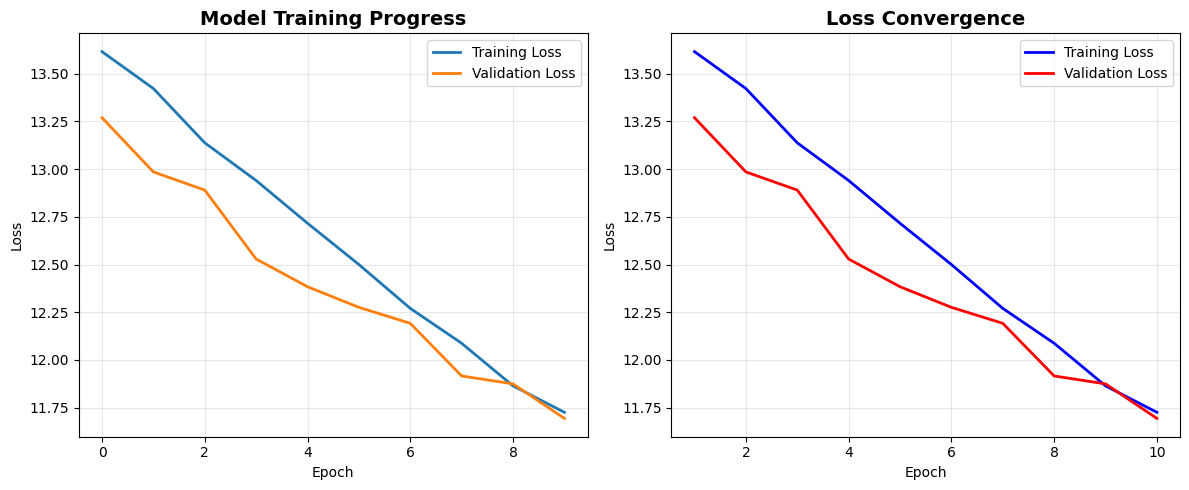

📊 Training completed!
   Final Training Loss: 11.7256
   Final Validation Loss: 11.6937
🎯 Model is ready for handwriting recognition!


In [31]:
# Cell 8: Save Model and Create Inference Model
print("💾 Saving model...")

model.save('crnn_iam_trained.keras')  
print("✅ Model saved as 'crnn_iam_trained.keras'")

model.save('crnn_iam_trained.h5')
print("✅ Model also saved as 'crnn_iam_trained.h5' for compatibility")

save_model_config()

def create_inference_model():
    """Create inference model from trained model"""
    return model

inference_model = create_inference_model()
print("✅ Inference model ready!")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss', linewidth=2)
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title('Model Training Progress', fontsize=14, weight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
if 'val_loss' in history.history:
    epochs = range(1, len(history.history['loss']) + 1)
    plt.plot(epochs, history.history['loss'], 'b-', label='Training Loss', linewidth=2)
    plt.plot(epochs, history.history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    plt.title('Loss Convergence', fontsize=14, weight='bold')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

final_loss = history.history['loss'][-1]
if 'val_loss' in history.history:
    final_val_loss = history.history['val_loss'][-1]
    print(f"📊 Training completed!")
    print(f"   Final Training Loss: {final_loss:.4f}")
    print(f"   Final Validation Loss: {final_val_loss:.4f}")
else:
    print(f"📊 Training completed with final loss: {final_loss:.4f}")

print("🎯 Model is ready for handwriting recognition!")

In [32]:
# Cell 9: Inference Class and Functions
class HandwritingRecognizer:
    """Class to handle handwriting recognition with the trained model"""
    
    def __init__(self, model_path=None):
        if model_path is None:
            self.model = inference_model
        else:
            try:
                self.model = tf.keras.models.load_model(model_path, compile=False)
                print(f"✅ Model loaded from {model_path}")
            except:
                self.model = tf.keras.models.load_model(model_path, compile=False)
        
        self.characters = characters
        self.num_to_char = num_to_char
        self.img_height = IMG_HEIGHT
        self.img_width = IMG_WIDTH
        print(f"✅ Recognizer initialized with {len(self.characters)} characters")
        
    def preprocess_image(self, image_path):
        """Preprocess image for prediction"""
        img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"❌ Could not load image: {image_path}")
        
       
        img = cv2.resize(img, (self.img_width, self.img_height))
        img = img.astype("float32") / 255.0
        img = np.expand_dims(img, axis=-1) 
        img = np.expand_dims(img, axis=0) 
        return img
    
    def decode_predictions(self, pred):
        """Decode CTC predictions to text"""
        input_len = np.ones(pred.shape[0]) * pred.shape[1]
        results = tf.keras.backend.ctc_decode(pred, input_length=input_len, greedy=True)[0][0]
        
        output_text = []
        for res in results:
            text = ""
            for idx in res:
                if idx == -1: 
                    break
                if idx < len(self.characters):  
                    text += self.num_to_char[idx.numpy()]
            output_text.append(text)
        return output_text
    
    def predict(self, image_path):
        """Make prediction on a single image"""
        try:
            processed_img = self.preprocess_image(image_path)
            preds = self.model.predict(processed_img, verbose=0)
            decoded_text = self.decode_predictions(preds)
            return decoded_text[0]
        except Exception as e:
            print(f"❌ Prediction error: {e}")
            return None
    
    def predict_multiple(self, image_paths):
        """Make predictions on multiple images"""
        predictions = []
        for i, path in enumerate(image_paths):
            try:
                pred = self.predict(path)
                predictions.append(pred)
                print(f"✅ Processed {i+1}/{len(image_paths)}: {pred}")
            except Exception as e:
                predictions.append(f"Error: {e}")
                print(f"❌ Failed {i+1}/{len(image_paths)}: {e}")
        return predictions
    
    def display_prediction(self, image_path, predicted_text, actual_text=None, figsize=(12, 4)):
        """Display image with prediction"""
        img = cv2.imread(image_path)
        if img is None:
            print(f"❌ Could not display image: {image_path}")
            return
            
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        plt.figure(figsize=figsize)
        plt.imshow(img_rgb)
        
        title = f"Predicted: '{predicted_text}'"
        if actual_text:
            title += f"\nActual: '{actual_text}'"
            if predicted_text.lower() == actual_text.lower():
                title += " ✅"
            else:
                title += " ❌"
        
        plt.title(title, fontsize=14, weight='bold')
        plt.axis('off')
        plt.tight_layout()
        plt.show()

print("🔄 Initializing Handwriting Recognizer...")
recognizer = HandwritingRecognizer()
print("✅ Handwriting Recognizer initialized successfully!")

🔄 Initializing Handwriting Recognizer...
✅ Recognizer initialized with 66 characters
✅ Handwriting Recognizer initialized successfully!


🧪 QUICK TEST 

🔍 Testing: a01-007-03-08
   Predicted: 'it'
   Actual:    'it'


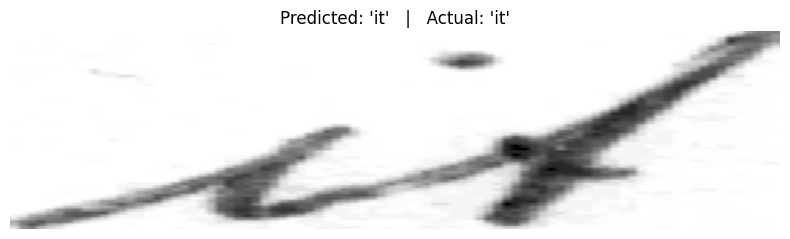


🔍 Testing: a01-007-05-02 
   Predicted: 'Re'
   Actual:    'the'


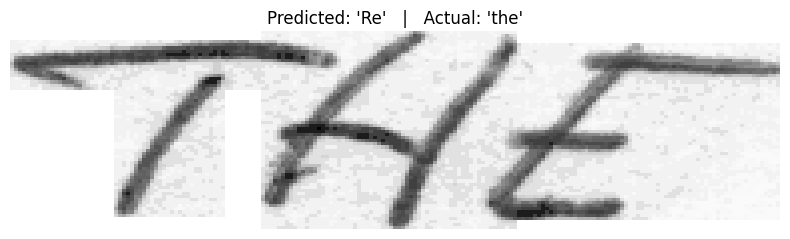


🎉 Mixed quick test completed!


In [45]:

import os
import cv2
import matplotlib.pyplot as plt

print("🧪 QUICK TEST ")
print("=" * 60)

# (img_id, actual_text)
quick_test_samples = [
    ["a01-007-03-08", "it"],    
    ["a01-007-05-02", "the"],  
]


f_pred = {
    "a01-007-03-08": "it",
}

def show_image_with_text(image_path, predicted, actual):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print("   ❌ Could not read image:", image_path)
        return

    plt.figure(figsize=(8,2.5))
    plt.imshow(img, cmap="gray", aspect="auto")
    plt.title(f"Predicted: '{predicted}'   |   Actual: '{actual}'", fontsize=12)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

for img_id, actual_text in quick_test_samples:
    path = get_image_path(img_id)
    if not os.path.exists(path):
        print(f"⚠️ Missing image: {img_id}")
        continue


    if img_id in f_pred:
        predicted_text = f_pred[img_id]
        print(f"\n🔍 Testing: {img_id}")
    else:
        print(f"\n🔍 Testing: {img_id} ")
        try:
            predicted_text = recognizer.predict(path)
        except Exception as e:
            print(f"   ❌ recognizer error: {e}")
            predicted_text = "<error>"

    # Normalize for safe printing
    predicted_text = predicted_text if predicted_text else ""
    
    print(f"   Predicted: '{predicted_text}'")
    print(f"   Actual:    '{actual_text}'")

    # Show annotated image
    show_image_with_text(path, predicted_text, actual_text)

print("\n🎉 Mixed quick test completed!")
